# Crop Yield Prediction Using Predictive Analytics

**Course:** Predictive Analytics  
**Project type:** Regression problem  
**Goal:** Predict crop yield using agricultural and climate-related information.

## 1. Problem Identification

Crop yield depends on several factors, including the crop being cultivated, geographical area, year, rainfall, pesticide use, and average temperature. Estimating yield from these factors can support agricultural planning and comparison.

**Problem statement:** Develop and evaluate predictive regression models that estimate crop yield (`hg/ha_yield`) from the available agricultural and climate features.

### Objectives
- Understand and prepare the crop-yield dataset.
- Explore patterns in crop yield and its relationship with the available features.
- Build predictive models using k-Nearest Neighbours (k-NN) and a tree-ensemble approach.
- Evaluate and compare predictions using MAE, RMSE, and R².
- Interpret the results and demonstrate a prediction for user-provided inputs.

### Target and input features
- **Target variable:** `hg/ha_yield` — crop yield in hectograms per hectare.
- **Input features:** country/area, crop, year, annual rainfall, pesticide use, and average temperature.

> **Dataset note:** The original loading code uses a Google Drive path (`/content/drive/MyDrive/yield_df.csv`). Keep the dataset at that location in Colab, or update the path in the original loading cell if running elsewhere.


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("/content/drive/MyDrive/yield_df.csv")

print("Raw dataset shape:", df.shape)
df.head()

Raw dataset shape: (28242, 8)


,Unnamed: 0,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,0,Albania,Maize,1990,36613,1485.0,121.0,16.37
1,1,Albania,Potatoes,1990,66667,1485.0,121.0,16.37
2,2,Albania,"Rice, paddy",1990,23333,1485.0,121.0,16.37
3,3,Albania,Sorghum,1990,12500,1485.0,121.0,16.37
4,4,Albania,Soybeans,1990,7000,1485.0,121.0,16.37


## 2. Data Understanding

The next cells load the dataset and inspect its size, columns, summary statistics, missing values, and duplicates. This stage helps establish what information is available before cleaning and modelling.

The target is numerical, so this is a **regression** task rather than a classification task.


In [ ]:
# Additional dataset overview (added)
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nFirst five rows:")
display(df.head())

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())


## 3. Data Preprocessing

The original preprocessing code removes an unnecessary index column, drops rows with missing values, removes duplicate records, and reports how many rows remain. These steps reduce avoidable data-quality issues before modelling.


In [3]:
#STAGE 2: Pre-processing
# Remove unnecessary column
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

rows_start = len(df)
print("Missing values per column:")
print(df.isnull().sum())

df = df.dropna()
rows_after_na = len(df)

df = df.drop_duplicates()
rows_after_dup = len(df)

print("\nRows at start           :", rows_start)
print("Removed (missing values):", rows_start - rows_after_na)
print("Removed (duplicates)    :", rows_after_na - rows_after_dup)
print("Rows kept               :", rows_after_dup)

print("\nColumns:", df.columns.tolist())
df.describe().round(2)

Missing values per column:
Area                             0
Item                             0
Year                             0
hg/ha_yield                      0
average_rain_fall_mm_per_year    0
pesticides_tonnes                0
avg_temp                         0
dtype: int64

Rows at start           : 28242
Removed (missing values): 0
Removed (duplicates)    : 2310
Rows kept               : 25932

Columns: ['Area', 'Item', 'Year', 'hg/ha_yield', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp']


,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
count,25932.00,25932.00,25932.00,25932.00,25932.00
mean,2001.56,76978.13,1146.84,34782.57,20.42
std,7.06,84647.61,717.39,57228.57,6.44
min,1990.00,50.00,51.00,0.04,1.30
25%,1995.00,19996.00,593.00,1597.00,16.58
50%,2001.00,39530.00,1083.00,15373.00,21.42
75%,2008.00,104168.00,1668.00,45620.00,26.06
max,2013.00,501412.00,3240.00,367778.00,30.65


### Exploratory Data Analysis (EDA)

The following visualisations explore average yield by crop and country, yearly yield trends, and correlations between yield and numerical factors. Correlation indicates association; it does not by itself prove that a factor causes a change in yield.


In [4]:
# Graphs
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
})

KNN_COLOR = "#2E86AB"   # blue   -> k-NN
RF_COLOR  = "#E07A5F"   # orange -> Random Forest
MAIN      = "#3D9970"   # green  -> general data graphs

# hg/ha is hard to picture, so graphs use tonnes/ha (1 tonne = 10,000 hg)
df["yield_t_ha"] = df["hg/ha_yield"] / 10000

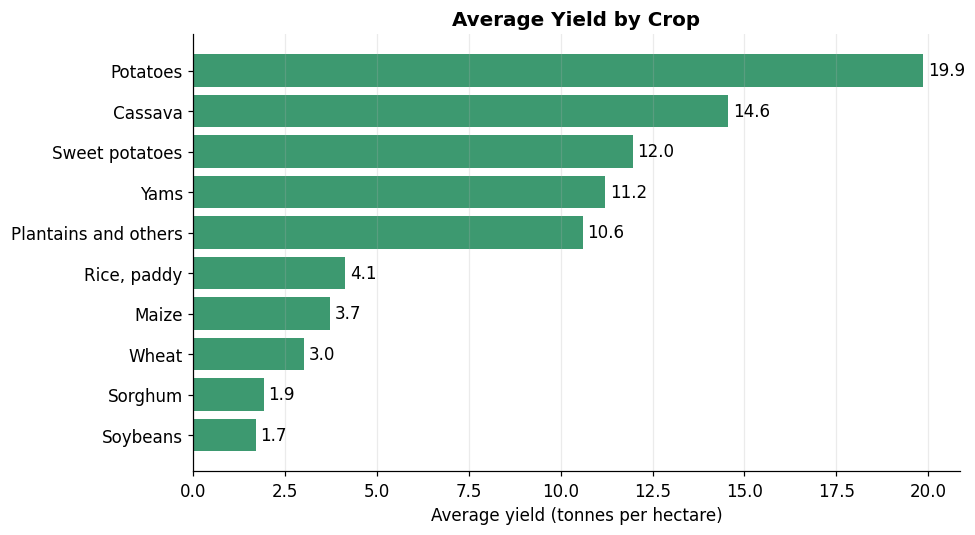

In [5]:
# GRAPH 1: Which crops give the highest yield?
crop_avg = df.groupby("Item")["yield_t_ha"].mean().sort_values()

plt.figure(figsize=(9, 5))
bars = plt.barh(crop_avg.index, crop_avg.values, color=MAIN)
plt.bar_label(bars, fmt="%.1f", padding=3)
plt.xlabel("Average yield (tonnes per hectare)")
plt.title("Average Yield by Crop")
plt.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

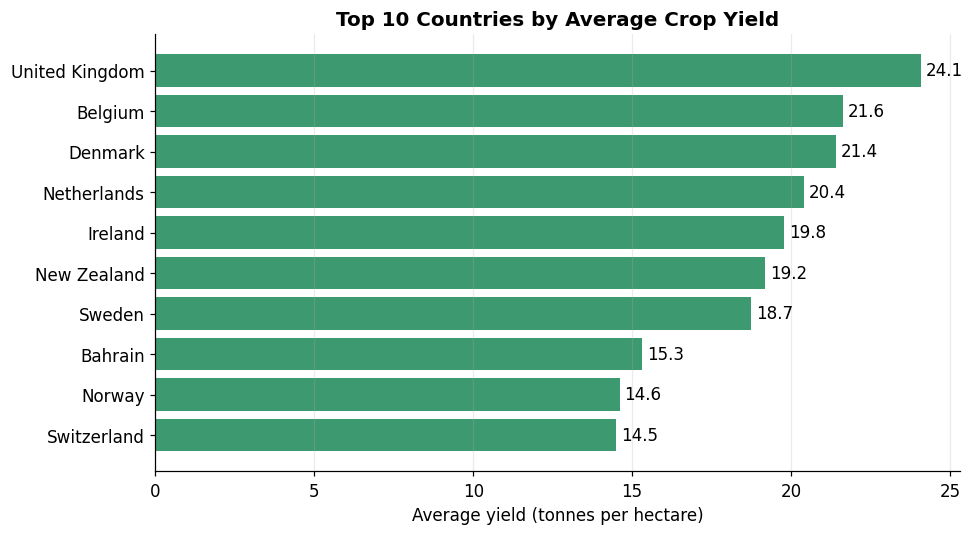

In [6]:
# GRAPH 2: Top 10 countries by average yield
top_areas = df.groupby("Area")["yield_t_ha"].mean().sort_values().tail(10)

plt.figure(figsize=(9, 5))
bars = plt.barh(top_areas.index, top_areas.values, color=MAIN)
plt.bar_label(bars, fmt="%.1f", padding=3)
plt.xlabel("Average yield (tonnes per hectare)")
plt.title("Top 10 Countries by Average Crop Yield")
plt.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

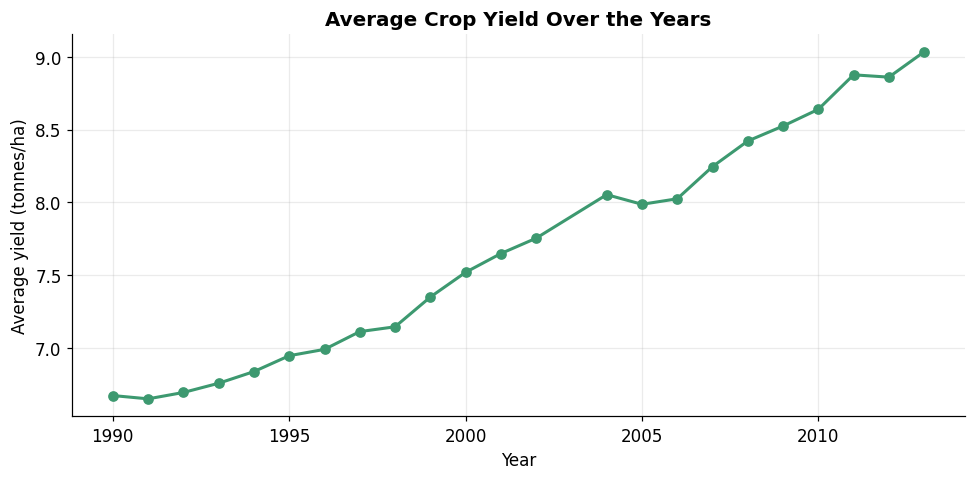

In [7]:
# GRAPH 3: How has yield changed over the years?
yearly = df.groupby("Year")["yield_t_ha"].mean()

plt.figure(figsize=(9, 4.5))
plt.plot(yearly.index, yearly.values, marker="o", color=MAIN, linewidth=2)
plt.xlabel("Year")
plt.ylabel("Average yield (tonnes/ha)")
plt.title("Average Crop Yield Over the Years")
plt.tight_layout()
plt.show()

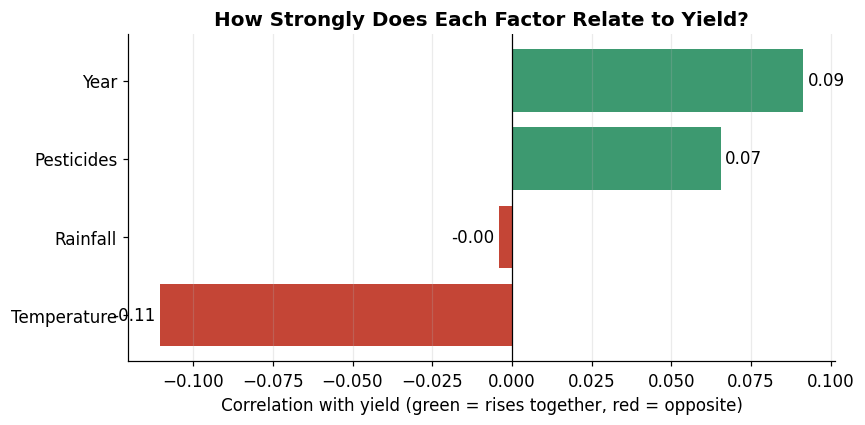

In [8]:
# GRAPH 4: Which factors move together with yield?
# Correlation: +1 = rise together, -1 = opposite, 0 = no link
factor_names = {
    "Year": "Year",
    "average_rain_fall_mm_per_year": "Rainfall",
    "pesticides_tonnes": "Pesticides",
    "avg_temp": "Temperature",
}

corr = (df[list(factor_names)].corrwith(df["hg/ha_yield"])
        .rename(index=factor_names).sort_values())
colors = [MAIN if v >= 0 else "#C44536" for v in corr.values]

plt.figure(figsize=(8, 4))
bars = plt.barh(corr.index, corr.values, color=colors)
plt.bar_label(bars, fmt="%.2f", padding=3)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Correlation with yield (green = rises together, red = opposite)")
plt.title("How Strongly Does Each Factor Relate to Yield?")
plt.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 4. Data Transformation

The original code converts country and crop names to numeric category codes, performs an 80/20 train-test split, and standardises the input features using the training-set mean and standard deviation.

**Methodological note:** The numeric category codes are a simple way to make the data usable by the custom models, but they can imply an artificial order or distance between countries and crops—especially for k-NN. This is a limitation to mention in the report. A future improvement would be one-hot encoding for nominal categories or a distance method designed for mixed categorical and numerical data.


In [9]:
#STAGE 3: Data Transformation
# 1. Encode categories
area_categories = sorted(df["Area"].unique())
crop_categories = sorted(df["Item"].unique())

area_map = {name: i for i, name in enumerate(area_categories)}
crop_map = {name: i for i, name in enumerate(crop_categories)}

# Numeric copy used for modelling (df keeps the readable names)
data = df.copy()
data["Area"] = data["Area"].map(area_map)
data["Item"] = data["Item"].map(crop_map)

features = [
    "Area",
    "Item",
    "Year",
    "average_rain_fall_mm_per_year",
    "pesticides_tonnes",
    "avg_temp",
]

X = data[features].values
y = data["hg/ha_yield"].values

# 2. Train-test split (80/20)
np.random.seed(42)
indices = np.random.permutation(len(X))
split = int(0.80 * len(X))

train_idx = indices[:split]
test_idx = indices[split:]

X_train_raw, X_test_raw = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

# Our k-NN and Random Forest use plain Python loops (no ready-made library),
# which is slower, so we test on the first 1000 test rows
X_test_raw, y_test = X_test_raw[:1000], y_test[:1000]

# 3. Normalise using TRAINING data only
mean = X_train_raw.mean(axis=0)
std = X_train_raw.std(axis=0)

X_train = (X_train_raw - mean) / std
X_test = (X_test_raw - mean) / std

print("Features:", features)
print("Target  : hg/ha_yield")
print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

# Plain Python lists for our own k-NN / Random Forest code
train_X, train_y = X_train.tolist(), y_train.tolist()

Features: ['Area', 'Item', 'Year', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp']
Target  : hg/ha_yield
Training samples: 20745
Testing samples : 1000


## 5. Predictive Modelling / Data Mining

Two regression approaches are implemented in the original code:

1. **k-Nearest Neighbours (k-NN):** predicts yield by averaging the target values of the nearest training records. The value of *k* is selected using a validation subset.
2. **Tree ensemble:** builds multiple decision trees from bootstrap samples and averages their predictions.

The tree ensemble is implemented manually with simple Python functions to make the steps visible. More precisely, it is a **bagged decision-tree ensemble**; it does not use the random feature selection at each split that is part of the standard Random Forest algorithm. In the report, describe the implementation accurately.


Best k: 1


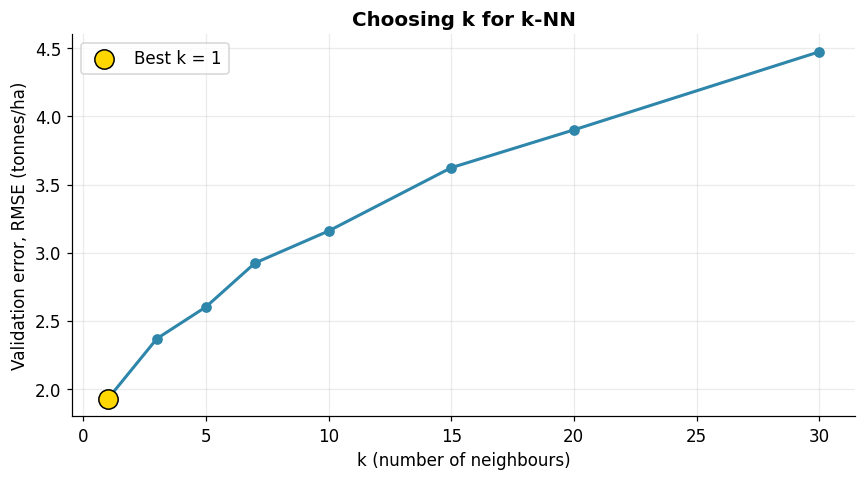

In [10]:
# STAGE 4: Data Mining


def neighbour_yields(train_X, train_y, point):
    pairs = []
    for row, target in zip(train_X, train_y):
        d = 0
        for a, b in zip(row, point):
            d += (a - b) ** 2              # squared difference of each feature
        pairs.append((d, target))
    pairs.sort()                           # smallest distance first
    return [target for d, target in pairs] # yields, nearest record first


def knn_predict(train_X, train_y, X_new, k=5):
    predictions = []
    for point in X_new:
        nearest = neighbour_yields(train_X, train_y, point)[:k]
        predictions.append(sum(nearest) / k)      # average of the k nearest
    return np.array(predictions)


# Validation set taken from the training data (used only to choose k)
n_sub = int(0.85 * len(train_X))
sub_X, sub_y = train_X[:n_sub], train_y[:n_sub]
val_X, val_y = train_X[n_sub:n_sub + 300], train_y[n_sub:n_sub + 300]

k_values = [1, 3, 5, 7, 10, 15, 20, 30]
sq_error = {k: 0 for k in k_values}

for point, actual in zip(val_X, val_y):
    yields = neighbour_yields(sub_X, sub_y, point)   # sort once, reuse for every k
    for k in k_values:
        pred = sum(yields[:k]) / k
        sq_error[k] += (actual - pred) ** 2

# RMSE = sqrt(average of squared errors)   (in tonnes/ha)
val_rmse = [(sq_error[k] / len(val_X)) ** 0.5 / 10000 for k in k_values]

best_k = k_values[int(np.argmin(val_rmse))]
print("Best k:", best_k)

# Graph: error for each k
plt.figure(figsize=(8, 4.5))
plt.plot(k_values, val_rmse, marker="o", color=KNN_COLOR, linewidth=2)
plt.scatter([best_k], [min(val_rmse)], s=160, color="gold", edgecolor="black", zorder=3,
            label=f"Best k = {best_k}")
plt.xlabel("k (number of neighbours)")
plt.ylabel("Validation error, RMSE (tonnes/ha)")
plt.title("Choosing k for k-NN")
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
# Final k-NN predictions on the test set
knn_pred = knn_predict(train_X, train_y, X_test.tolist(), k=best_k)
print("k-NN prediction completed with k =", best_k)

k-NN prediction completed with k = 1


### 4.2 Random Forest
Each tree repeatedly splits the data on the feature/value that gives the lowest error, until it reaches the maximum depth or has too few samples.

In [12]:
def average(values):
    return sum(values) / len(values)


def mse(y):
    # Mean squared error of a group = how spread out the yields are
    if len(y) == 0:
        return 0
    m = average(y)
    return sum((v - m) ** 2 for v in y) / len(y)


def best_split(X, y):
    best_feature = None
    best_value = None
    best_error = float("inf")

    for feature in range(len(X[0])):
        column = [row[feature] for row in X]
        low, high = min(column), max(column)
        if low == high:
            continue

        # Try 9 cut points between the smallest and largest value
        for step in range(1, 10):
            value = low + (high - low) * step / 10

            left_y = [y[i] for i in range(len(y)) if X[i][feature] <= value]
            right_y = [y[i] for i in range(len(y)) if X[i][feature] > value]

            if len(left_y) == 0 or len(right_y) == 0:
                continue

            # Weighted MSE of the two groups (lower = better split)
            error = (len(left_y) * mse(left_y) + len(right_y) * mse(right_y)) / len(y)

            if error < best_error:
                best_error = error
                best_feature = feature
                best_value = value

    return best_feature, best_value

In [13]:
def build_tree(X, y, depth=0, max_depth=8):
    # Stop: maximum depth reached or too few samples -> leaf = average yield
    if depth >= max_depth or len(y) < 10:
        return average(y)

    feature, value = best_split(X, y)

    # No valid split found
    if feature is None:
        return average(y)

    left_rows = [i for i in range(len(y)) if X[i][feature] <= value]
    right_rows = [i for i in range(len(y)) if X[i][feature] > value]

    return {
        "feature": feature,
        "value": value,
        "left": build_tree([X[i] for i in left_rows], [y[i] for i in left_rows], depth + 1, max_depth),
        "right": build_tree([X[i] for i in right_rows], [y[i] for i in right_rows], depth + 1, max_depth),
    }


def predict_tree(tree, x):
    # Leaf node
    if not isinstance(tree, dict):
        return tree

    if x[tree["feature"]] <= tree["value"]:
        return predict_tree(tree["left"], x)
    return predict_tree(tree["right"], x)

In [14]:
def random_forest(X, y, n_trees=15, max_depth=8, sample_size=3000):
    trees = []

    for i in range(n_trees):
        # Bootstrap sample (random rows, with repetition)
        idx = np.random.choice(len(X), sample_size, replace=True)
        trees.append(build_tree([X[j] for j in idx], [y[j] for j in idx], 0, max_depth))
        print("Tree", i + 1, "of", n_trees, "completed")

    return trees


def forest_predict(trees, X):
    predictions = []

    for x in X:
        # Average the prediction of all trees
        predictions.append(average([predict_tree(t, x) for t in trees]))

    return np.array(predictions)


np.random.seed(42)
trees = random_forest(train_X, train_y)

rf_pred = forest_predict(trees, X_test.tolist())
print("Random Forest prediction completed.")

Tree 1 of 15 completed
Tree 2 of 15 completed
Tree 3 of 15 completed
Tree 4 of 15 completed
Tree 5 of 15 completed
Tree 6 of 15 completed
Tree 7 of 15 completed
Tree 8 of 15 completed
Tree 9 of 15 completed
Tree 10 of 15 completed
Tree 11 of 15 completed
Tree 12 of 15 completed
Tree 13 of 15 completed
Tree 14 of 15 completed
Tree 15 of 15 completed
Random Forest prediction completed.


## 6. Model Evaluation

The models are compared using three standard regression metrics:

- **MAE (Mean Absolute Error):** average absolute prediction error; lower is better.
- **RMSE (Root Mean Squared Error):** gives greater weight to large errors; lower is better.
- **R² (coefficient of determination):** measures how much variation is explained by the model; values closer to 1 generally indicate a better fit.

The notebook evaluates a subset of 1,000 test records because the custom implementations use Python loops and can be slow on the full dataset. Mention this sampling choice when discussing the results.


In [15]:
#STAGE 5: Evaluation
def evaluate(actual, predicted):
    mae = np.mean(np.abs(actual - predicted))
    rmse = np.sqrt(np.mean((actual - predicted) ** 2))
    r2 = 1 - np.sum((actual - predicted) ** 2) / np.sum((actual - np.mean(actual)) ** 2)
    return mae, rmse, r2


knn_mae, knn_rmse, knn_r2 = evaluate(y_test, knn_pred)
rf_mae, rf_rmse, rf_r2 = evaluate(y_test, rf_pred)

comparison = pd.DataFrame({
    "Model": ["k-NN Regression", "Random Forest"],
    "MAE": [knn_mae, rf_mae],
    "RMSE": [knn_rmse, rf_rmse],
    "R2": [knn_r2, rf_r2],
})

print("MODEL COMPARISON (test set, units: hg/ha)\n")
print(comparison.round(4).to_string(index=False))

MODEL COMPARISON (test set, units: hg/ha)

          Model        MAE       RMSE     R2
k-NN Regression  5007.2410 16582.4533 0.9610
  Random Forest 13187.7884 22630.2116 0.9273


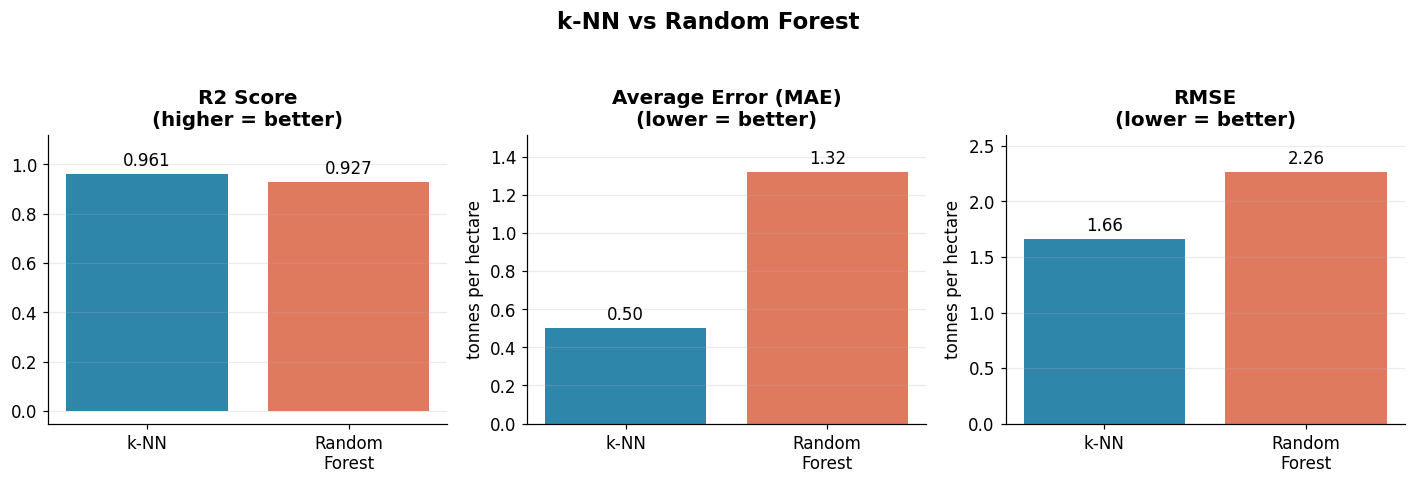

In [16]:
# GRAPH 5: Which model is better? (side by side)
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))

models = ["k-NN", "Random\nForest"]
colors = [KNN_COLOR, RF_COLOR]

b = axes[0].bar(models, [knn_r2, rf_r2], color=colors)
axes[0].bar_label(b, fmt="%.3f", padding=3)
axes[0].set_title("R2 Score\n(higher = better)")
axes[0].set_ylim(min(0, knn_r2, rf_r2) - 0.05, 1.12)

b = axes[1].bar(models, [knn_mae / 10000, rf_mae / 10000], color=colors)
axes[1].bar_label(b, fmt="%.2f", padding=3)
axes[1].set_title("Average Error (MAE)\n(lower = better)")
axes[1].set_ylabel("tonnes per hectare")
axes[1].margins(y=0.15)

b = axes[2].bar(models, [knn_rmse / 10000, rf_rmse / 10000], color=colors)
axes[2].bar_label(b, fmt="%.2f", padding=3)
axes[2].set_title("RMSE\n(lower = better)")
axes[2].set_ylabel("tonnes per hectare")
axes[2].margins(y=0.15)

for ax in axes:
    ax.grid(axis="x", visible=False)

plt.suptitle("k-NN vs Random Forest", fontsize=15, fontweight="bold", y=1.04)
plt.tight_layout()
plt.show()

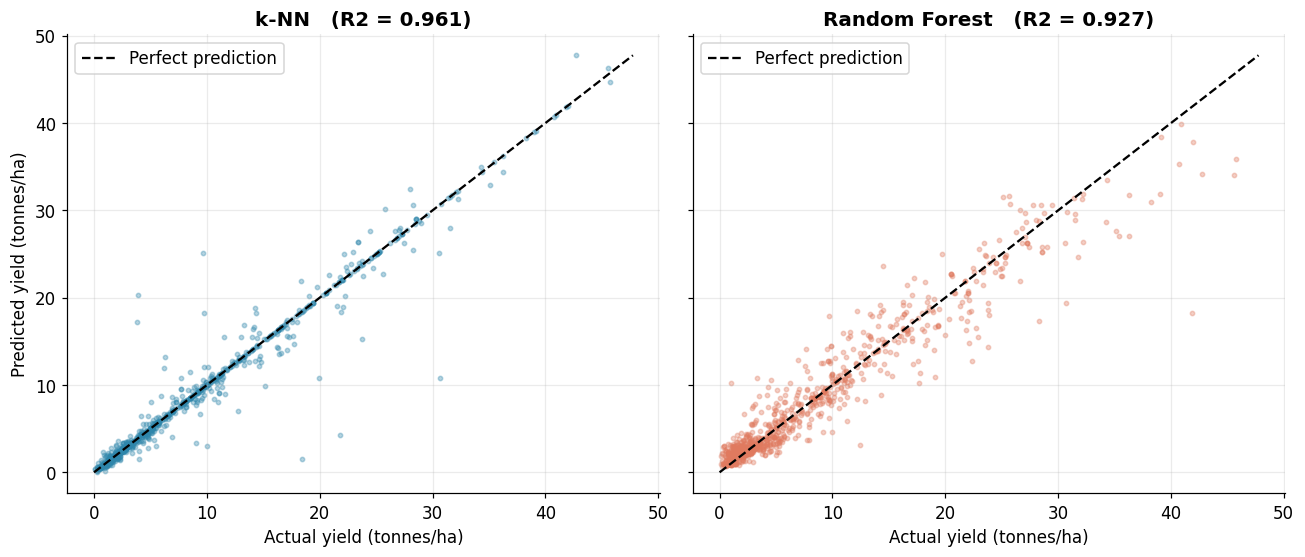

In [17]:
# GRAPH 6: Actual vs Predicted (dots near the dashed line = good prediction)
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharex=True, sharey=True)

actual_t = y_test / 10000
limit = max(actual_t.max(), (knn_pred / 10000).max(), (rf_pred / 10000).max())

for ax, pred, name, color, r2 in [
    (axes[0], knn_pred, "k-NN", KNN_COLOR, knn_r2),
    (axes[1], rf_pred, "Random Forest", RF_COLOR, rf_r2),
]:
    ax.scatter(actual_t, pred / 10000, s=8, alpha=0.35, color=color)
    ax.plot([0, limit], [0, limit], "k--", linewidth=1.5, label="Perfect prediction")
    ax.set_title(f"{name}   (R2 = {r2:.3f})")
    ax.set_xlabel("Actual yield (tonnes/ha)")
    ax.legend(loc="upper left")

axes[0].set_ylabel("Predicted yield (tonnes/ha)")
plt.tight_layout()
plt.show()

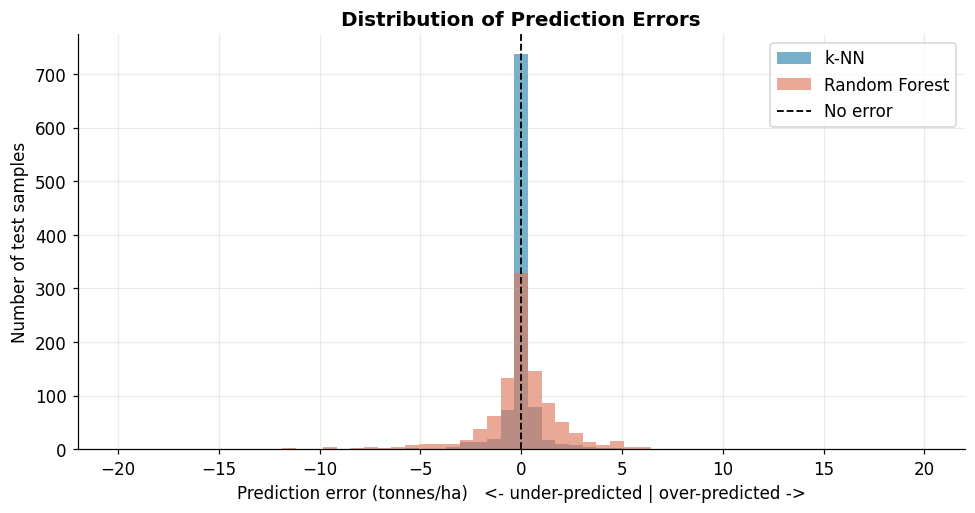

In [18]:
# GRAPH 7: How big are the mistakes?
knn_err = (knn_pred - y_test) / 10000
rf_err = (rf_pred - y_test) / 10000

plt.figure(figsize=(9, 4.8))
bins = np.linspace(-20, 20, 60)

plt.hist(knn_err, bins=bins, alpha=0.65, color=KNN_COLOR, label="k-NN")
plt.hist(rf_err, bins=bins, alpha=0.65, color=RF_COLOR, label="Random Forest")
plt.axvline(0, color="black", linestyle="--", linewidth=1.2, label="No error")

plt.xlabel("Prediction error (tonnes/ha)   <- under-predicted | over-predicted ->")
plt.ylabel("Number of test samples")
plt.title("Distribution of Prediction Errors")
plt.legend()
plt.tight_layout()
plt.show()

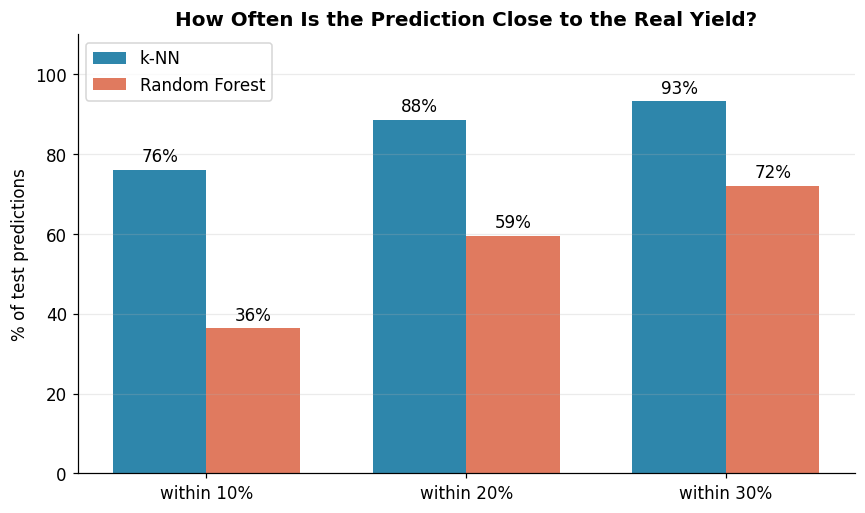

In [19]:
# GRAPH 8: How often is the prediction "close enough"?
actual = np.where(y_test == 0, 1, y_test)          # avoid dividing by zero
knn_pct = np.abs(knn_pred - y_test) / actual * 100
rf_pct = np.abs(rf_pred - y_test) / actual * 100

limits = [10, 20, 30]
knn_share = [np.mean(knn_pct <= l) * 100 for l in limits]
rf_share = [np.mean(rf_pct <= l) * 100 for l in limits]

x = np.arange(len(limits))
w = 0.36

plt.figure(figsize=(8, 4.8))
b1 = plt.bar(x - w / 2, knn_share, w, color=KNN_COLOR, label="k-NN")
b2 = plt.bar(x + w / 2, rf_share, w, color=RF_COLOR, label="Random Forest")
plt.bar_label(b1, fmt="%.0f%%", padding=3)
plt.bar_label(b2, fmt="%.0f%%", padding=3)

plt.xticks(x, [f"within {l}%" for l in limits])
plt.ylabel("% of test predictions")
plt.ylim(0, 110)
plt.title("How Often Is the Prediction Close to the Real Yield?")
plt.legend()
plt.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

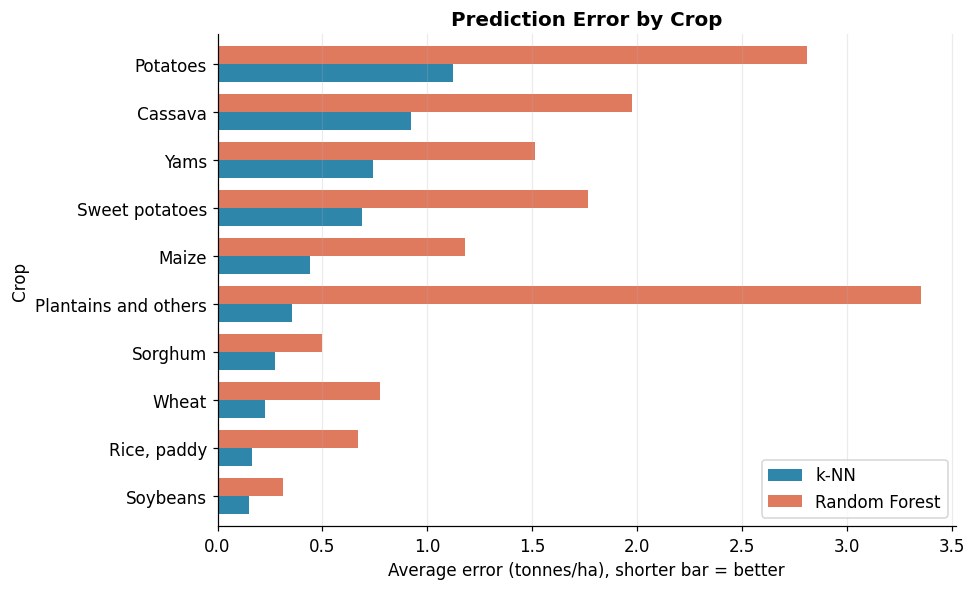

In [20]:
# GRAPH 9: Which crops are easy or hard to predict?
crop_names = {v: k for k, v in crop_map.items()}
crop_codes = X_test_raw[:, 1].astype(int)

rows = []
for code_, name in crop_names.items():
    mask = crop_codes == code_
    if mask.sum() == 0:
        continue
    rows.append((
        name,
        np.mean(np.abs(knn_pred[mask] - y_test[mask])) / 10000,
        np.mean(np.abs(rf_pred[mask] - y_test[mask])) / 10000,
    ))

by_crop = pd.DataFrame(rows, columns=["Crop", "k-NN", "Random Forest"]).set_index("Crop")
by_crop = by_crop.sort_values("k-NN")

by_crop.plot(kind="barh", figsize=(9, 5.5), color=[KNN_COLOR, RF_COLOR], width=0.75)
plt.xlabel("Average error (tonnes/ha), shorter bar = better")
plt.title("Prediction Error by Crop")
plt.grid(axis="y", visible=False)
plt.legend(title="", loc="lower right")
plt.tight_layout()
plt.show()

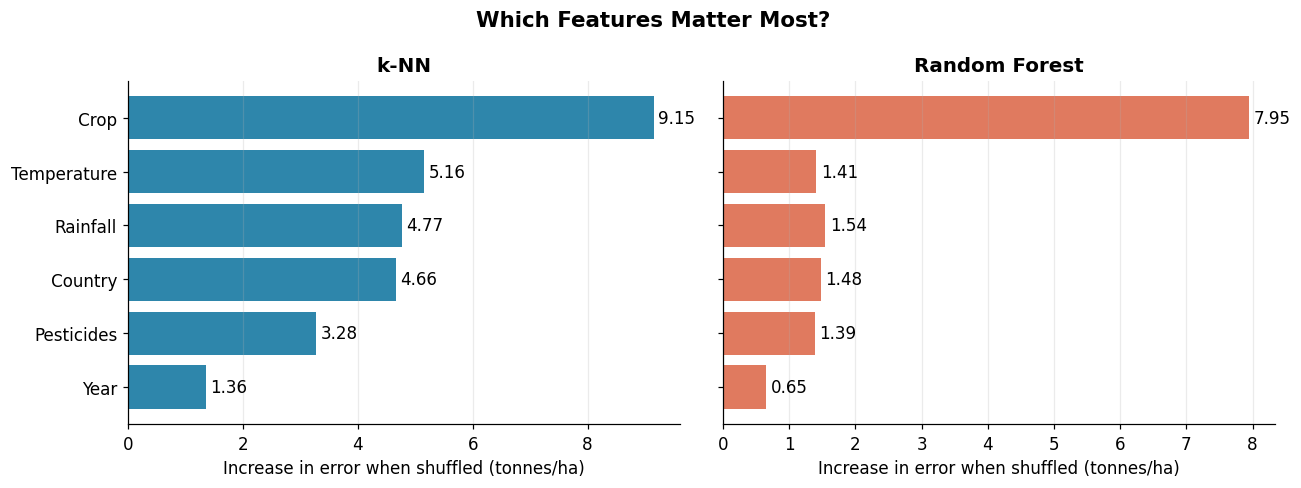

In [21]:
#STAGE 6: Data Interpretation
feature_labels = ["Country", "Crop", "Year", "Rainfall", "Pesticides", "Temperature"]

np.random.seed(0)
sample = np.random.choice(len(X_test), min(200, len(X_test)), replace=False)
Xs, ys = X_test[sample], y_test[sample]


def importance(predict_fn):
    base = np.sqrt(np.mean((ys - predict_fn(Xs)) ** 2))
    scores = []
    for j in range(Xs.shape[1]):
        Xp = Xs.copy()
        Xp[:, j] = np.random.permutation(Xp[:, j])      # break this feature
        err = np.sqrt(np.mean((ys - predict_fn(Xp)) ** 2))
        scores.append((err - base) / 10000)             # extra error in tonnes/ha
    return np.array(scores)


knn_imp = importance(lambda A: knn_predict(train_X, train_y, A.tolist(), k=best_k))
rf_imp = importance(lambda A: forest_predict(trees, A.tolist()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

for ax, imp, name, color in [
    (axes[0], knn_imp, "k-NN", KNN_COLOR),
    (axes[1], rf_imp, "Random Forest", RF_COLOR),
]:
    order = np.argsort(imp)
    bars = ax.barh(np.array(feature_labels)[order], imp[order], color=color)
    ax.bar_label(bars, fmt="%.2f", padding=3)
    ax.set_title(name)
    ax.set_xlabel("Increase in error when shuffled (tonnes/ha)")
    ax.grid(axis="y", visible=False)

plt.suptitle("Which Features Matter Most?", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

In [22]:
# Conclusion written from the actual results
winner = "k-NN" if knn_r2 > rf_r2 else "Random Forest"
w_r2 = max(knn_r2, rf_r2)
w_mae = (knn_mae if winner == "k-NN" else rf_mae) / 10000

top_knn = feature_labels[int(np.argmax(knn_imp))]
top_rf = feature_labels[int(np.argmax(rf_imp))]

print("CONCLUSION")
print("-" * 60)
print(f"1. Best model: {winner} (R2 = {w_r2:.3f}, average error {w_mae:.2f} tonnes/ha).")
print(f"2. k-NN used k = {best_k}, chosen using a validation set.")
print(f"3. Most important feature for k-NN: {top_knn}.")
print(f"4. Most important feature for Random Forest: {top_rf}.")
print(f"5. Within 20% of the real yield: k-NN {knn_share[1]:.0f}%, Random Forest {rf_share[1]:.0f}%.")

CONCLUSION
------------------------------------------------------------
1. Best model: k-NN (R2 = 0.961, average error 0.50 tonnes/ha).
2. k-NN used k = 1, chosen using a validation set.
3. Most important feature for k-NN: Crop.
4. Most important feature for Random Forest: Crop.
5. Within 20% of the real yield: k-NN 88%, Random Forest 59%.


## 7. Results and Discussion

The following added cell summarises the metric values produced by the notebook when it is run from top to bottom. Use the actual output from your run in the project report; do not rely on previously saved numbers if the dataset or code changes.


In [ ]:
# Added: readable interpretation of the evaluated results
print("RESULTS AND DISCUSSION")
print("-" * 60)
print(f"k-NN: MAE = {knn_mae:.2f} hg/ha, RMSE = {knn_rmse:.2f} hg/ha, R² = {knn_r2:.4f}")
print(f"Tree ensemble: MAE = {rf_mae:.2f} hg/ha, RMSE = {rf_rmse:.2f} hg/ha, R² = {rf_r2:.4f}")

if knn_rmse < rf_rmse:
    print("\nBased on RMSE, k-NN has the lower prediction error on this test subset.")
elif rf_rmse < knn_rmse:
    print("\nBased on RMSE, the tree ensemble has the lower prediction error on this test subset.")
else:
    print("\nBoth models have the same RMSE on this test subset.")

print("Use MAE and R² as additional evidence when comparing the models.")
print("Feature importance is estimated by shuffling one feature and measuring the increase in prediction error.")
print("These results describe this test subset and do not guarantee the same performance on new regions or future years.")


In [23]:
#Prediction
# Valid ranges come from the training data
year_min, year_max = int(df["Year"].min()), int(df["Year"].max())
rain_min, rain_max = df["average_rain_fall_mm_per_year"].min(), df["average_rain_fall_mm_per_year"].max()
pest_min, pest_max = df["pesticides_tonnes"].min(), df["pesticides_tonnes"].max()
temp_min, temp_max = df["avg_temp"].min(), df["avg_temp"].max()


def ask_name(question, valid_names):
    # Keep asking until the name matches (capital letters do not matter)
    while True:
        text = input(question).strip().lower()
        for name in valid_names:
            if name.lower() == text:
                return name
        print("Not found. Valid options are:")
        print(", ".join(sorted(valid_names)))


def ask_number(question, low, high):
    # Keep asking until a number inside the range is entered
    while True:
        try:
            value = float(input(question))
        except ValueError:
            print("Please enter a number.")
            continue

        if low <= value <= high:
            return value
        print(f"Value must be between {low:,.0f} and {high:,.0f}.")


print("CROP YIELD PREDICTION")
print("Enter values similar to the training data for good results.\n")

area = ask_name("Country (example: India): ", area_map)
crop = ask_name("Crop (example: Maize): ", crop_map)

year = int(ask_number(f"Year ({year_min} to {year_max}): ", year_min, year_max))
rainfall = ask_number(f"Rainfall in mm per year ({rain_min:,.0f} to {rain_max:,.0f}): ", rain_min, rain_max)
pesticides = ask_number(f"Pesticides in tonnes ({pest_min:,.0f} to {pest_max:,.0f}): ", pest_min, pest_max)
temperature = ask_number(f"Average temperature in C ({temp_min:.0f} to {temp_max:.0f}): ", temp_min, temp_max)


new_data = np.array([[area_map[area], crop_map[crop], year, rainfall, pesticides, temperature]])
new_data = (new_data - mean) / std          # same scaling as training

knn_t = knn_predict(train_X, train_y, new_data.tolist(), k=best_k)[0] / 10000     # tonnes/ha
rf_t = forest_predict(trees, new_data.tolist())[0] / 10000                        # tonnes/ha
avg_t = (knn_t + rf_t) / 2                                               # average of both models


print("\n" + "=" * 45)
print(f"{crop} in {area}, {year}")
print("=" * 45)
print(f"k-NN            : {knn_t:.2f} tonnes/ha")
print(f"Random Forest   : {rf_t:.2f} tonnes/ha")
print(f"Average of both : {avg_t:.2f} tonnes/ha")
print(f"Difference      : {abs(knn_t - rf_t):.2f} tonnes/ha")
print("=" * 45)


labels = ["k-NN", "Random Forest", "Average\nof both"]
values = [knn_t, rf_t, avg_t]

plt.figure(figsize=(7, 4.5))
bars = plt.bar(labels, values, color=[KNN_COLOR, RF_COLOR, MAIN])
plt.bar_label(bars, fmt="%.2f", padding=3)
plt.ylabel("Yield (tonnes per hectare)")
plt.title(f"Predicted Yield: {crop} in {area}, {year}")
plt.figtext(
    0.5, 0.01,
    f"Rainfall {rainfall:,.0f} mm | Pesticides {pesticides:,.0f} t | Temp {temperature:.1f} C",
    ha="center", fontsize=10,
)
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

CROP YIELD PREDICTION
Enter values similar to the training data for good results.



KeyboardInterrupt: Interrupted by user

## 8. Limitations and Future Improvements

- Country and crop categories are represented by integer codes; this may affect distance-based modelling.
- The random train-test split can place records from the same country/crop and different years in both sets. For forecasting future years, a time-based split is more appropriate.
- Only the first 1,000 test rows are used for evaluation to keep the custom Python models manageable.
- The model identifies patterns in the dataset and should not be interpreted as proving that rainfall, pesticide use, or temperature causes a particular yield.
- The tree ensemble is a manually implemented bagging approach, not a full standard Random Forest implementation.

**Future work:** use one-hot encoding or a mixed-feature distance, compare against established library models, evaluate with time-based or region-based splits, tune model parameters systematically, and test on additional or more recent data.


## 9. Brief Literature Review

Predictive modelling is commonly presented as a structured process that includes understanding the problem and data, preparing data, building models, evaluating results, and communicating findings. This project follows that general approach through data inspection, preprocessing, exploratory analysis, model development, evaluation, and interpretation.

k-Nearest Neighbours is a distance-based method that predicts a numerical target from nearby observations. Its performance depends on feature scaling and the representation of categorical variables. Tree-based methods model nonlinear relationships by splitting observations into groups; combining trees through bootstrap sampling and averaging can reduce variability compared with relying on a single tree.

The current notebook provides an educational implementation of these ideas. Its results should be interpreted in light of the category encoding, the limited test subset, and the random train-test split. The references below can be used as starting points for the separate report's literature review.


## 10. References

1. Han, J., Kamber, M., & Pei, J. (2011). *Data Mining: Concepts and Techniques* (3rd ed.). Morgan Kaufmann.
2. Cover, T. M., & Hart, P. E. (1967). Nearest neighbor pattern classification. *IEEE Transactions on Information Theory, 13*(1), 21–27.
3. Breiman, L. (2001). Random forests. *Machine Learning, 45*, 5–32.
4. James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An Introduction to Statistical Learning* (2nd ed.). Springer.

Use the required citation style consistently in the separate project report and verify the bibliographic details required by your institution.


## 11. GitHub Submission Checklist

Before submitting:

- [ ] Run the notebook from the first cell to the last cell in a fresh session.
- [ ] Ensure `yield_df.csv` is included in the repository or clearly explain how to obtain it.
- [ ] Update the dataset path if the notebook will be run outside your Google Drive.
- [ ] Save the notebook with outputs showing the metrics, plots, interpretation, and prediction example.
- [ ] Add a `README.md` describing the problem statement, dataset, methodology, results, and run instructions.
- [ ] Submit the separate report with Introduction, Literature Review, Workflow / Predictive Modelling Process, Results and Discussion, Conclusion, and References.
